In [1]:

%pip install -q numpy pandas scikit-learn matplotlib seaborn


In [2]:

import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0


In [3]:

from sklearn.datasets import fetch_lfw_people
import numpy as np
import pandas as pd

print("Downloading/loading LFW dataset...")

lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5,
    color=True
)

images = lfw.images
labels = lfw.target
people = lfw.target_names

print("Images shape:", images.shape)
print("Number of images:", len(images))
print("Number of identities:", len(people))
print("Image data type:", images.dtype)
print("Pixel range:", images.min(), "to", images.max())


Downloading/loading LFW dataset...
Images shape: (3023, 62, 47, 3)
Number of images: 3023
Number of identities: 62
Image data type: float32
Pixel range: 0.0 to 1.0


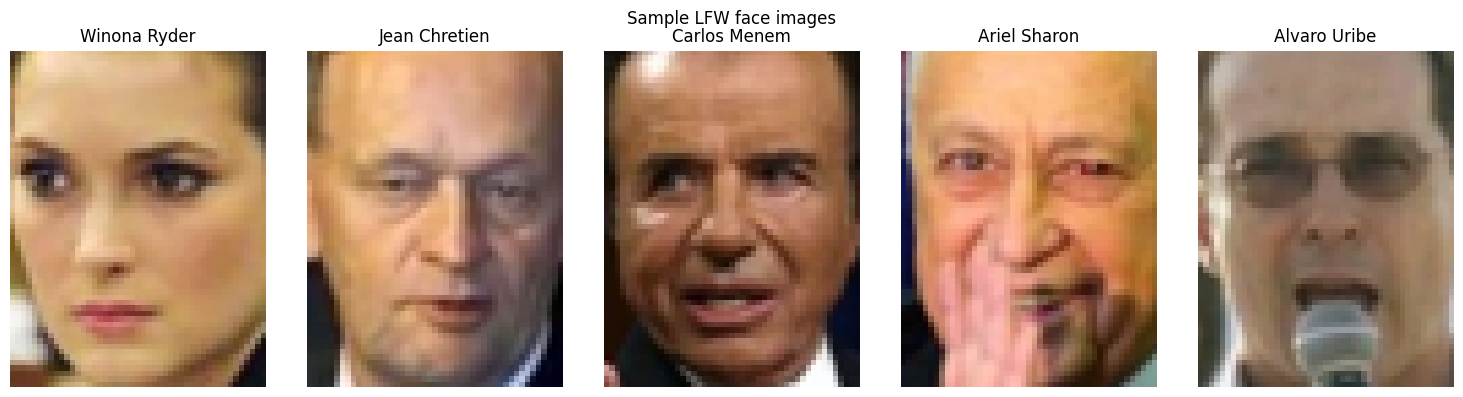

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(np.clip(images[i], 0, 1))
    ax.set_title(str(people[labels[i]]))
    ax.axis("off")

plt.suptitle("Sample LFW face images")
plt.tight_layout()
plt.show()


In [5]:

import numpy as np
import pandas as pd

# Check dataset dimensions and identity distribution
print("Total images:", len(images))
print("Unique identities:", len(np.unique(labels)))
print("Image shape:", images.shape[1:])

identity_counts = pd.Series(labels).value_counts().sort_values(ascending=False)

print("\nImages per identity:")
print(identity_counts.describe())

# Keep only identities with at least 20 images
eligible_ids = identity_counts[identity_counts >= 20].index.to_numpy()

print("\nEligible identities:", len(eligible_ids))
print("Images belonging to eligible identities:",
      int(identity_counts.loc[eligible_ids].sum()))


Total images: 3023
Unique identities: 62
Image shape: (62, 47, 3)

Images per identity:
count     62.000000
mean      48.758065
std       71.086345
min       20.000000
25%       23.000000
50%       31.000000
75%       42.000000
max      530.000000
Name: count, dtype: float64

Eligible identities: 62
Images belonging to eligible identities: 3023


In [6]:

%pip install -q facenet-pytorch


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 79.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 MB 18.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [7]:

import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

try:
    import torchvision
    print("Torchvision version:", torchvision.__version__)
except Exception as e:
    print("Torchvision error:", repr(e))


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu


In [8]:

%pip install facenet-pytorch -v


Streaming output truncated to the last 5000 lines.
    Found link https://files.pythonhosted.org/packages/d3/9e/3473113204e96b3f9633938f0a2de7f807cd1d7cc7988befcd0e4c61d7ec/cython-3.2.0b3-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (from https://pypi.org/simple/cython/) (requires-python:>=3.8), version: 3.2.0b3
    Skipping link: none of the wheel's tags (cp313-cp313-win_amd64) are compatible (run pip debug --verbose to show compatible tags): https://files.pythonhosted.org/packages/88/d9/1a683ae0bbc9f964cd74d0725aa0d16118e7eb03b534830007a4d8c07845/cython-3.2.0b3-cp313-cp313-win_amd64.whl (from https://pypi.org/simple/cython/) (requires-python:>=3.8)
    Skipping link: none of the wheel's tags (cp314-cp314-macosx_11_0_arm64) are compatible (run pip debug --verbose to show compatible tags): https://files.pythonhosted.org/packages/3d/2d/1eecda06eef42fa58d7c7399a224d876bd9a7c6535abaaffe6396c436a3a/cython-3.2.0b3-cp314-cp314-macosx_11_0_arm64.whl (from h

In [1]:

%pip install -q transformers


In [2]:

import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.11.0+cpu
Transformers: 5.20.1
CUDA available: False


In [5]:
import torch
import numpy as np
from transformers import AutoImageProcessor, AutoModel
from PIL import Image
from sklearn.datasets import fetch_lfw_people

# Ensure dataset is loaded in the current runtime session
try:
    images
    labels
    people
except NameError:
    print("Variables not found. Loading LFW dataset...")
    lfw = fetch_lfw_people(min_faces_per_person=20, resize=0.5, color=True)
    images = lfw.images
    labels = lfw.target
    people = lfw.target_names

MODEL_NAME = "google/vit-base-patch16-224"

print("Loading model:", MODEL_NAME)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.eval()

# Test one LFW image
sample = np.clip(images[0] * 255, 0, 255).astype(np.uint8)
sample_image = Image.fromarray(sample)

inputs = processor(images=sample_image, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

# Use the CLS token representation (first token) from the last hidden state as the embedding
embedding = outputs.last_hidden_state[:, 0, :]

print("Model loaded successfully.")
print("Embedding shape:", tuple(embedding.shape))
print("All values finite:", torch.isfinite(embedding).all().item())

Variables not found. Loading LFW dataset...
Loading model: google/vit-base-patch16-224


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Embedding shape: (1, 768)
All values finite: True


In [6]:

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Check that the dataset and model variables exist
print("Images:", images.shape)
print("Number of identities:", len(people))
print("Model:", MODEL_NAME)

model.eval()
all_embeddings = []

BATCH_SIZE = 16

for start in tqdm(range(0, len(images), BATCH_SIZE)):
    batch_images = []

    for img in images[start:start + BATCH_SIZE]:
        img_uint8 = np.clip(img * 255, 0, 255).astype(np.uint8)
        batch_images.append(Image.fromarray(img_uint8))

    inputs = processor(images=batch_images, return_tensors="pt")

    with torch.no_grad():
        outputs = model(**inputs)

        # Extract the model's pooled image features
        batch_embeddings = outputs.last_hidden_state[:, 0, :]

    all_embeddings.append(batch_embeddings.cpu().numpy())

embeddings = np.concatenate(all_embeddings, axis=0)

print("Embedding matrix shape:", embeddings.shape)
print("All values finite:", np.isfinite(embeddings).all())
print("Number of images:", len(embeddings))


Images: (3023, 62, 47, 3)
Number of identities: 62
Model: google/vit-base-patch16-224


  0%|          | 0/189 [00:00<?, ?it/s]

Embedding matrix shape: (3023, 768)
All values finite: True
Number of images: 3023


In [7]:

embedding_df = pd.DataFrame(embeddings)
embedding_df["identity_label"] = labels

embedding_df.to_csv(
    "lfw_vit_embeddings.csv",
    index=False
)

print("Saved: lfw_vit_embeddings.csv")
print("Rows and columns:", embedding_df.shape)
display(embedding_df.head())


Saved: lfw_vit_embeddings.csv
Rows and columns: (3023, 769)


,0,1,2,3,4,5,6,7,8,9,...,759,760,761,762,763,764,765,766,767,identity_label
0,1.445126,-0.275947,-2.486759,0.688646,-0.727520,-0.316534,2.009735,-0.029465,2.002846,0.024270,...,0.111501,-0.854688,-1.168884,1.235318,0.732669,1.168769,-0.381234,-1.591758,0.148663,61
1,0.894929,0.593413,-2.136880,1.322477,-0.087418,0.117707,1.572676,1.176135,0.072677,-0.490512,...,0.016100,1.377785,-0.721704,0.242011,0.141415,-0.591075,-0.856515,0.421215,-1.250429,25
2,-0.732671,0.638454,-1.932821,1.318641,0.374618,-0.311061,1.291052,1.322841,-0.089708,-0.238329,...,0.009332,0.510414,-1.693065,0.107993,0.322471,-0.644578,-0.168452,0.521841,-0.409709,9
3,0.142825,1.161895,-2.169971,0.441072,0.419739,-0.489438,0.471285,0.580722,-0.604124,-0.464962,...,-0.058881,0.875505,-0.338035,-0.046223,0.394094,-1.065154,0.004991,1.246743,-1.273321,5
4,-1.239340,-1.049585,-0.670516,0.793044,0.577204,0.194682,0.164315,1.630161,-1.108566,-1.350289,...,0.079717,-0.217188,-1.552062,0.734037,0.017011,-1.294054,0.182419,0.317357,-0.333472,1


In [8]:

import numpy as np
import pandas as pd

df = pd.read_csv("lfw_vit_embeddings.csv")

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float64)
y = df["identity_label"].to_numpy()

print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Non-finite feature values:", int((~np.isfinite(X)).sum()))
print("Unique identities:", len(np.unique(y)))
print("Images per identity — min:", int(pd.Series(y).value_counts().min()))
print("Images per identity — median:", float(pd.Series(y).value_counts().median()))
print("Images per identity — max:", int(pd.Series(y).value_counts().max()))
print("Feature mean (overall):", float(X.mean()))
print("Feature standard deviation (overall):", float(X.std()))
print("Exact duplicate feature rows:", int(pd.DataFrame(X).duplicated().sum()))


Dataset shape: (3023, 769)
Missing values: 0
Non-finite feature values: 0
Unique identities: 62
Images per identity — min: 20
Images per identity — median: 31.0
Images per identity — max: 530
Feature mean (overall): -0.023133252986952544
Feature standard deviation (overall): 0.8675548817996513
Exact duplicate feature rows: 0


In [9]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Load the saved dataset
df = pd.read_csv("lfw_vit_embeddings.csv")

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float64)
y = df["identity_label"].to_numpy()

SEED = 2026
rng = np.random.default_rng(SEED)

# Split each identity into separate reference and test pools.
# This avoids putting the same image in both pools.
reference_indices = []
test_indices = []

for identity in np.unique(y):
    idx = np.flatnonzero(y == identity)
    idx = rng.permutation(idx)

    n_ref = max(1, int(0.5 * len(idx)))
    reference_indices.extend(idx[:n_ref])
    test_indices.extend(idx[n_ref:])

reference_indices = np.array(reference_indices)
test_indices = np.array(test_indices)

# Randomize each pool independently
reference_indices = rng.permutation(reference_indices)
test_indices = rng.permutation(test_indices)

X_reference = X[reference_indices]
y_reference = y[reference_indices]

X_test = X[test_indices]
y_test = y[test_indices]

print("Reference images:", len(X_reference))
print("Test images:", len(X_test))
print("Reference identities:", len(np.unique(y_reference)))
print("Test identities:", len(np.unique(y_test)))
print(
    "Image-index overlap:",
    len(set(reference_indices) & set(test_indices))
)

# Standardize using reference statistics only
reference_mean = X_reference.mean(axis=0)
reference_std = X_reference.std(axis=0)
reference_std[reference_std < 1e-8] = 1.0

Z_reference = (X_reference - reference_mean) / reference_std
Z_test = (X_test - reference_mean) / reference_std

# Controlled stream: baseline followed by an artificial mean shift
WINDOW_SIZE = 20
SHIFT_START = 100
SHIFT_MAGNITUDE = 0.5

# Use a test stream long enough to include baseline and post-shift windows
n_windows = min(200, len(Z_test) // WINDOW_SIZE)
stream = Z_test[:n_windows * WINDOW_SIZE].copy()

# Add a controlled shift to the second half of the stream
shift_index = min(SHIFT_START * WINDOW_SIZE, len(stream))
stream[shift_index:] += SHIFT_MAGNITUDE

print("Stream shape:", stream.shape)
print("Window size:", WINDOW_SIZE)
print("Number of windows:", len(stream) // WINDOW_SIZE)
print("Shift begins at sample index:", shift_index)
print("Shift magnitude:", SHIFT_MAGNITUDE)
print("Random seed:", SEED)


Reference images: 1497
Test images: 1526
Reference identities: 62
Test identities: 62
Image-index overlap: 0
Stream shape: (1520, 768)
Window size: 20
Number of windows: 76
Shift begins at sample index: 1520
Shift magnitude: 0.5
Random seed: 2026


In [10]:

# Rebuild the controlled stream correctly

WINDOW_SIZE = 20
BASELINE_WINDOWS = 40
SHIFT_MAGNITUDE = 0.5

TOTAL_WINDOWS = min(
    76,
    len(Z_test) // WINDOW_SIZE
)

assert TOTAL_WINDOWS > BASELINE_WINDOWS, (
    "Not enough test windows for a post-shift period."
)

stream = Z_test[:TOTAL_WINDOWS * WINDOW_SIZE].copy()

SHIFT_START = BASELINE_WINDOWS * WINDOW_SIZE

# Artificial mean shift begins after the baseline period
stream[SHIFT_START:] += SHIFT_MAGNITUDE

print("Stream shape:", stream.shape)
print("Total windows:", len(stream) // WINDOW_SIZE)
print("Baseline windows:", BASELINE_WINDOWS)
print("Post-shift windows:", TOTAL_WINDOWS - BASELINE_WINDOWS)
print("Shift begins at sample index:", SHIFT_START)
print("Shift magnitude:", SHIFT_MAGNITUDE)

assert SHIFT_START < len(stream)
assert np.any(stream[SHIFT_START:] != Z_test[SHIFT_START:SHIFT_START + len(stream[SHIFT_START:])])
print("Controlled shift successfully applied.")


Stream shape: (1520, 768)
Total windows: 76
Baseline windows: 40
Post-shift windows: 36
Shift begins at sample index: 800
Shift magnitude: 0.5
Controlled shift successfully applied.


In [11]:

import numpy as np
import pandas as pd

# Convert the stream into non-overlapping windows
windows = stream.reshape(-1, WINDOW_SIZE, stream.shape[1])

# Reference mean in standardized feature space
ref_mean = Z_reference.mean(axis=0)

# Euclidean distance between each window mean and reference mean
window_means = windows.mean(axis=1)
scores = np.linalg.norm(window_means - ref_mean, axis=1)

# Calibrate threshold using baseline windows only
baseline_scores = scores[:BASELINE_WINDOWS]
threshold = np.quantile(baseline_scores, 0.99)

# Flag windows exceeding the threshold
alarms = scores > threshold

# Evaluate before and after the known change point
pre_change_alarms = int(alarms[:BASELINE_WINDOWS].sum())
post_change_alarms = alarms[BASELINE_WINDOWS:]

first_detection = (
    BASELINE_WINDOWS + int(np.flatnonzero(post_change_alarms)[0])
    if post_change_alarms.any()
    else None
)

if first_detection is not None:
    detection_delay_windows = first_detection - BASELINE_WINDOWS
    detection_delay_samples = detection_delay_windows * WINDOW_SIZE
else:
    detection_delay_windows = None
    detection_delay_samples = None

results = pd.DataFrame({
    "window_index": np.arange(len(scores)),
    "score": scores,
    "alarm": alarms,
    "period": [
        "baseline" if i < BASELINE_WINDOWS else "post_shift"
        for i in range(len(scores))
    ]
})

print("Threshold:", float(threshold))
print("Baseline alarms:", pre_change_alarms, "/", BASELINE_WINDOWS)
print("Baseline alarm rate:", pre_change_alarms / BASELINE_WINDOWS)
print("Post-shift alarm count:", int(post_change_alarms.sum()), "/", len(post_change_alarms))
print("First detected window:", first_detection)
print("Detection delay (windows):", detection_delay_windows)
print("Detection delay (samples):", detection_delay_samples)

display(results.head(10))
display(results.tail(10))


Threshold: 8.113430423240608
Baseline alarms: 1 / 40
Baseline alarm rate: 0.025
Post-shift alarm count: 36 / 36
First detected window: 40
Detection delay (windows): 0
Detection delay (samples): 0


,window_index,score,alarm,period
0,0,6.465296,False,baseline
1,1,5.267355,False,baseline
2,2,6.995506,False,baseline
3,3,8.163026,True,baseline
4,4,8.035857,False,baseline
5,5,5.721852,False,baseline
6,6,5.489880,False,baseline
7,7,5.856225,False,baseline
8,8,6.337852,False,baseline
9,9,6.148508,False,baseline


,window_index,score,alarm,period
66,66,15.386087,True,post_shift
67,67,14.960576,True,post_shift
68,68,15.234034,True,post_shift
69,69,15.509070,True,post_shift
70,70,15.953524,True,post_shift
71,71,14.985695,True,post_shift
72,72,15.132635,True,post_shift
73,73,14.722964,True,post_shift
74,74,15.582379,True,post_shift
75,75,14.971227,True,post_shift


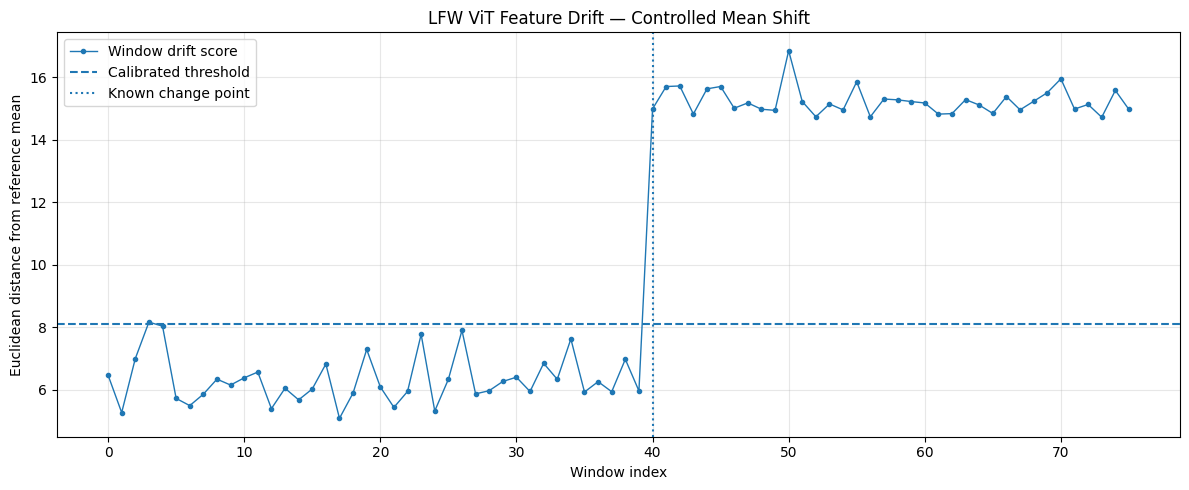

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    results["window_index"],
    results["score"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Window drift score"
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Calibrated threshold"
)

plt.axvline(
    BASELINE_WINDOWS,
    linestyle=":",
    label="Known change point"
)

plt.xlabel("Window index")
plt.ylabel("Euclidean distance from reference mean")
plt.title("LFW ViT Feature Drift — Controlled Mean Shift")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

import numpy as np
import pandas as pd

# Experiment settings
WINDOW_SIZE = 20
BASELINE_WINDOWS = 40
TOTAL_WINDOWS = 76
SHIFT_MAGNITUDES = [0.10, 0.25, 0.50]
SEEDS = range(2026, 2036)
TARGET_FALSE_ALARM_RATE = 0.01

# Reuse the previously standardized test features
# and reference features. Do not modify the existing stream.
results_multi = []

for shift_magnitude in SHIFT_MAGNITUDES:
    for seed in SEEDS:
        rng_trial = np.random.default_rng(seed)

        # Independently shuffle test examples for each trial
        order = rng_trial.permutation(len(Z_test))
        trial_data = Z_test[order]

        n_samples = TOTAL_WINDOWS * WINDOW_SIZE
        trial_data = trial_data[:n_samples].copy()

        if len(trial_data) < n_samples:
            raise ValueError("Not enough test samples for the requested windows.")

        shift_start = BASELINE_WINDOWS * WINDOW_SIZE
        trial_data[shift_start:] += shift_magnitude

        windows = trial_data.reshape(
            TOTAL_WINDOWS, WINDOW_SIZE, trial_data.shape[1]
        )

        window_means = windows.mean(axis=1)
        ref_mean = Z_reference.mean(axis=0)

        # Euclidean detector scores
        euclidean_scores = np.linalg.norm(
            window_means - ref_mean, axis=1
        )

        # Regularized Mahalanobis detector
        ref_cov = np.cov(Z_reference, rowvar=False)
        ridge = 1e-3
        ref_cov_reg = ref_cov + ridge * np.eye(ref_cov.shape[0])
        inv_cov = np.linalg.pinv(ref_cov_reg)

        differences = window_means - ref_mean
        mahalanobis_scores = np.sqrt(
            np.maximum(
                np.einsum(
                    "bi,ij,bj->b",
                    differences,
                    inv_cov,
                    differences
                ),
                0
            )
        )

        for detector_name, scores in [
            ("Euclidean", euclidean_scores),
            ("Mahalanobis", mahalanobis_scores)
        ]:
            # Calibrate on baseline windows only
            threshold = np.quantile(
                scores[:BASELINE_WINDOWS],
                1 - TARGET_FALSE_ALARM_RATE,
                method="higher"
            )

            alarms = scores > threshold
            baseline_false_alarms = int(
                alarms[:BASELINE_WINDOWS].sum()
            )
            post_alarms = alarms[BASELINE_WINDOWS:]

            detection_window = (
                BASELINE_WINDOWS + int(np.flatnonzero(post_alarms)[0])
                if post_alarms.any()
                else None
            )

            results_multi.append({
                "seed": seed,
                "shift_magnitude": shift_magnitude,
                "detector": detector_name,
                "threshold": float(threshold),
                "baseline_false_alarms": baseline_false_alarms,
                "baseline_windows": BASELINE_WINDOWS,
                "baseline_false_alarm_rate":
                    baseline_false_alarms / BASELINE_WINDOWS,
                "detected": detection_window is not None,
                "detection_delay_windows":
                    detection_window - BASELINE_WINDOWS
                    if detection_window is not None else np.nan,
                "detection_delay_samples":
                    (detection_window - BASELINE_WINDOWS) * WINDOW_SIZE
                    if detection_window is not None else np.nan,
                "post_shift_alarm_rate": float(post_alarms.mean())
            })

results_multi_df = pd.DataFrame(results_multi)

print("Completed trials:", len(results_multi_df))
display(results_multi_df.head(10))


Completed trials: 60


,seed,shift_magnitude,detector,threshold,baseline_false_alarms,baseline_windows,baseline_false_alarm_rate,detected,detection_delay_windows,detection_delay_samples,post_shift_alarm_rate
0,2026,0.1,Euclidean,8.653003,0,40,0.0,False,NaN,NaN,0.000000
1,2026,0.1,Mahalanobis,12.412963,0,40,0.0,True,0.0,0.0,1.000000
2,2027,0.1,Euclidean,7.947153,0,40,0.0,True,7.0,140.0,0.111111
3,2027,0.1,Mahalanobis,12.591241,0,40,0.0,True,0.0,0.0,1.000000
4,2028,0.1,Euclidean,9.949184,0,40,0.0,False,NaN,NaN,0.000000
5,2028,0.1,Mahalanobis,11.794691,0,40,0.0,True,0.0,0.0,1.000000
6,2029,0.1,Euclidean,7.383937,0,40,0.0,True,1.0,20.0,0.277778
7,2029,0.1,Mahalanobis,11.599648,0,40,0.0,True,0.0,0.0,1.000000
8,2030,0.1,Euclidean,8.710049,0,40,0.0,False,NaN,NaN,0.000000
9,2030,0.1,Mahalanobis,12.236007,0,40,0.0,True,0.0,0.0,1.000000


In [14]:

summary = (
    results_multi_df
    .groupby(["shift_magnitude", "detector"])
    .agg(
        trials=("detected", "count"),
        detections=("detected", "sum"),
        detection_rate=("detected", "mean"),
        mean_baseline_false_alarm_rate=(
            "baseline_false_alarm_rate", "mean"
        ),
        mean_detection_delay_windows=(
            "detection_delay_windows", "mean"
        ),
        mean_post_shift_alarm_rate=(
            "post_shift_alarm_rate", "mean"
        )
    )
    .reset_index()
)

display(summary.round(4))


,shift_magnitude,detector,trials,detections,detection_rate,mean_baseline_false_alarm_rate,mean_detection_delay_windows,mean_post_shift_alarm_rate
0,0.10,Euclidean,10,4,0.4,0.0,10.75,0.0583
1,0.10,Mahalanobis,10,10,1.0,0.0,0.00,1.0000
2,0.25,Euclidean,10,10,1.0,0.0,0.30,0.8694
3,0.25,Mahalanobis,10,10,1.0,0.0,0.00,1.0000
4,0.50,Euclidean,10,10,1.0,0.0,0.00,1.0000
5,0.50,Mahalanobis,10,10,1.0,0.0,0.00,1.0000


In [15]:

# Save trial-level and summary results
results_multi_df.to_csv(
    "lfw_repeated_seed_trial_results.csv",
    index=False
)

summary.to_csv(
    "lfw_repeated_seed_summary.csv",
    index=False
)

print("Saved trial results: lfw_repeated_seed_trial_results.csv")
print("Saved summary: lfw_repeated_seed_summary.csv")

# Download the two CSV files to your computer
from google.colab import files

files.download("lfw_repeated_seed_trial_results.csv")
files.download("lfw_repeated_seed_summary.csv")


Saved trial results: lfw_repeated_seed_trial_results.csv
Saved summary: lfw_repeated_seed_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

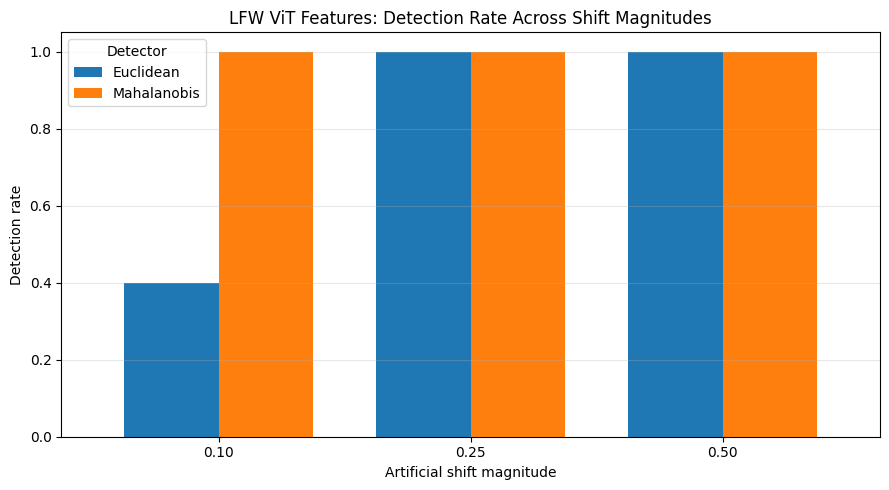

Saved plot: lfw_detection_rate_comparison.png


In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the actual experiment summary
summary = pd.read_csv("lfw_repeated_seed_summary.csv")

# Plot detection rate for each detector and shift magnitude
pivot = summary.pivot(
    index="shift_magnitude",
    columns="detector",
    values="detection_rate"
)

ax = pivot.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1.05),
    width=0.75
)

ax.set_title("LFW ViT Features: Detection Rate Across Shift Magnitudes")
ax.set_xlabel("Artificial shift magnitude")
ax.set_ylabel("Detection rate")
ax.set_xticklabels(
    [f"{x:.2f}" for x in pivot.index],
    rotation=0
)
ax.legend(title="Detector")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("lfw_detection_rate_comparison.png", dpi=300)
plt.show()

print("Saved plot: lfw_detection_rate_comparison.png")


In [17]:

from google.colab import files

files.download("lfw_detection_rate_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>